In [1]:
# ============================================================
# 0. SETUP: IMPOR + MUAT DATA (sebelumnya hilang -> penyebab NameError)
# ============================================================
import copy
import random
from pathlib import Path
 
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)
 
from dataset import prepare_client_data, TARGET, DROP_COLS
from model import build_model
 
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')
 
clients, scaler, feature_names = prepare_client_data(CLIENT_DIR)
 
 
def get_xy(st, split):
    c = clients[st]
    return c[f'X_{split}_t'], c[f'y_{split}_t']
 
 
# Sanity check data
n_fitur = next(iter(clients.values()))['X_train_t'].shape[1]
assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"
total_train = sum(len(c['y_train_t']) for c in clients.values())
assert scaler.n_samples_seen_ == total_train, "scaler tidak di-fit pada seluruh data train"
print(f"Client: {len(clients)} | Fitur: {n_fitur} | Total train: {total_train}")
 
# %%
# ============================================================
# 1. KONFIGURASI (multi-seed)
# ============================================================
DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EPOCHS     = 50
BATCH_SIZE = 64
LR         = 1e-3
PATIENCE   = 5
SEEDS      = [42, 0, 123, 1337, 3407]
 
METRIK = ['acc', 'prec', 'rec', 'f1', 'auc', 'prauc']
NAMA   = {'acc': 'Akurasi', 'prec': 'Presisi', 'rec': 'Recall',
          'f1': 'F1-score', 'auc': 'AUC', 'prauc': 'PR-AUC'}
SPLITS = ['val', 'test']
 
print("Device:", DEVICE, "| Seeds:", SEEDS)
 
 
def set_seed(seed):
    """Kunci semua sumber randomness agar tiap run reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

Client: 44 | Fitur: 69 | Total train: 59971
Device: cuda | Seeds: [42, 0, 123, 1337, 3407]


In [2]:

# %%
# ============================================================
# 2. FUNGSI TRAIN & EVALUASI
# ============================================================
def make_loader(X, y, shuffle, seed=None):
    ds = TensorDataset(X.float(), y.long())
    g = torch.Generator().manual_seed(seed) if (shuffle and seed is not None) else None
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, generator=g)
 
 
@torch.no_grad()
def predict_logits(model, X, bs=4096):
    model.eval()
    out = [model(X[i:i + bs].float().to(DEVICE)) for i in range(0, len(X), bs)]
    return torch.cat(out)
 
 
@torch.no_grad()
def evaluate(model, X, y, criterion=None):
    logits = predict_logits(model, X)
    prob = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
    pred = logits.argmax(dim=1).cpu().numpy()
    y_np = y.long().cpu().numpy()
    dua_kelas = len(np.unique(y_np)) > 1
 
    out = {
        'acc':   accuracy_score(y_np, pred),
        'prec':  precision_score(y_np, pred, zero_division=0),
        'rec':   recall_score(y_np, pred, zero_division=0),
        'f1':    f1_score(y_np, pred, zero_division=0),
        'auc':   roc_auc_score(y_np, prob) if dua_kelas else np.nan,
        'prauc': average_precision_score(y_np, prob) if dua_kelas else np.nan,
    }
    if criterion is not None:
        out['loss'] = criterion(logits, y.long().to(DEVICE)).item()
    return out
 
 
def train_local(X_train, y_train, X_val, y_val, seed, verbose=False):
    """Latih satu model lokal untuk satu seed; kembalikan (model terbaik, history)."""
    set_seed(seed)
    model = build_model(in_dim=X_train.shape[1], seed=seed).to(DEVICE)
 
    n_pos = int(y_train.sum())
    n_neg = len(y_train) - n_pos
    if n_pos > 0 and n_neg > 0:
        w = torch.tensor([len(y_train) / (2 * n_neg),
                          len(y_train) / (2 * n_pos)], dtype=torch.float32)
    else:
        w = torch.ones(2)
    criterion = nn.CrossEntropyLoss(weight=w.to(DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
 
    loader = make_loader(X_train, y_train, shuffle=True, seed=seed)
 
    best_loss, best_state, wait = float('inf'), None, 0
    history = []
 
    for epoch in range(1, EPOCHS + 1):
        model.train()
        running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(loader.dataset)
 
        val = evaluate(model, X_val, y_val, criterion)
        history.append({'epoch': epoch, 'train_loss': train_loss,
                        'val_loss': val['loss'], 'val_f1': val['f1'],
                        'val_prauc': val['prauc']})
        if verbose:
            print(f"  ep {epoch:02d} | train {train_loss:.4f} | "
                  f"val {val['loss']:.4f} | val_f1 {val['f1']:.4f}")
 
        if best_state is None or val['loss'] < best_loss - 1e-5:
            best_loss, wait = val['loss'], 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                break
 
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)
 
# %%
# ============================================================
# 3. LATIH SEMUA CLIENT x SEMUA SEED, EVALUASI VAL & TEST
# ============================================================
local_models, local_hist = {}, {}          # kunci: (seed, state)
rows = {s: [] for s in SPLITS}
 
for seed in SEEDS:
    print(f"\n######## SEED {seed} ########")
    for st in clients:
        X_tr, y_tr = get_xy(st, 'train')
        X_va, y_va = get_xy(st, 'val')
        X_te, y_te = get_xy(st, 'test')
 
        model, hist = train_local(X_tr, y_tr, X_va, y_va, seed=seed)
        res = {'val': evaluate(model, X_va, y_va),
               'test': evaluate(model, X_te, y_te)}
 
        local_models[(seed, st)] = model
        local_hist[(seed, st)]   = hist
        for s in SPLITS:
            rows[s].append({'seed': seed, 'state': st,
                            'epochs_run': len(hist), **res[s]})
 
        print(f"seed {seed} | state_{st:02d} | ep {len(hist):02d} | "
              f"VAL f1 {res['val']['f1']:.4f} prauc {res['val']['prauc']:.4f} | "
              f"TEST f1 {res['test']['f1']:.4f} prauc {res['test']['prauc']:.4f}")
 
# Data long: satu baris per (seed, state)
hasil_seed = {s: pd.DataFrame(rows[s]) for s in SPLITS}
 
# Agregasi antar seed per state: mean & std
KOL = METRIK + ['epochs_run']
HASIL     = {s: hasil_seed[s].groupby('state')[KOL].mean() for s in SPLITS}
HASIL_STD = {s: hasil_seed[s].groupby('state')[KOL].std(ddof=1) for s in SPLITS}
 
hasil_val   = HASIL['val']
hasil_test  = HASIL['test']
hasil_lokal = hasil_test                    # kompatibel dengan kode lama
 
 
def mean_pm_std(split, cols=METRIK, nd=4):
    m, s = HASIL[split][cols], HASIL_STD[split][cols]
    return m.round(nd).astype(str) + ' ± ' + s.round(nd).astype(str)
 
 
for s in SPLITS:
    print(f"\n=== {s.upper()}: mean ± std antar {len(SEEDS)} seed, per state ===")
    print(mean_pm_std(s).rename(columns=NAMA).to_string())
 
# %%
# ============================================================
# 4. STABILITAS ANTAR SEED
#    (rata-rata makro antar state per seed, lalu mean ± std antar seed)
# ============================================================
for s in SPLITS:
    per_seed = hasil_seed[s].groupby('seed')[METRIK].mean().loc[SEEDS]
    print(f"\n=== {s.upper()}: rata-rata makro antar state, per seed ===")
    print(per_seed.rename(columns=NAMA).round(4).to_string())
    print("--> mean ± std antar seed:")
    print((per_seed.mean().round(4).astype(str) + ' ± ' +
           per_seed.std(ddof=1).round(4).astype(str)).rename(index=NAMA).to_string())
 


######## SEED 42 ########
seed 42 | state_01 | ep 11 | VAL f1 0.5230 prauc 0.4966 | TEST f1 0.4524 prauc 0.4300
seed 42 | state_02 | ep 11 | VAL f1 0.4583 prauc 0.3929 | TEST f1 0.4299 prauc 0.3895
seed 42 | state_04 | ep 08 | VAL f1 0.4554 prauc 0.4356 | TEST f1 0.4505 prauc 0.4938
seed 42 | state_05 | ep 09 | VAL f1 0.5464 prauc 0.5427 | TEST f1 0.5296 prauc 0.4593
seed 42 | state_08 | ep 09 | VAL f1 0.4286 prauc 0.3441 | TEST f1 0.3851 prauc 0.3050
seed 42 | state_10 | ep 10 | VAL f1 0.4659 prauc 0.4364 | TEST f1 0.4542 prauc 0.3696
seed 42 | state_11 | ep 15 | VAL f1 0.4167 prauc 0.4541 | TEST f1 0.4211 prauc 0.4296
seed 42 | state_12 | ep 08 | VAL f1 0.4418 prauc 0.4019 | TEST f1 0.4910 prauc 0.4426
seed 42 | state_13 | ep 08 | VAL f1 0.5235 prauc 0.4719 | TEST f1 0.5646 prauc 0.5130
seed 42 | state_15 | ep 08 | VAL f1 0.4036 prauc 0.3554 | TEST f1 0.3760 prauc 0.3582
seed 42 | state_16 | ep 11 | VAL f1 0.4725 prauc 0.5277 | TEST f1 0.3906 prauc 0.4624
seed 42 | state_17 | ep 11 

=== Ringkasan antar client: VAL (mean 5 seed) ===
          Rata-rata (makro)  Std antar client  Rata-rata berbobot     Min     Max
Akurasi              0.6748            0.0227              0.6717  0.6292  0.7719
Presisi              0.3631            0.0375              0.3643  0.2821  0.4392
Recall               0.6573            0.0490              0.6703  0.5481  0.7452
F1-score             0.4664            0.0370              0.4707  0.3723  0.5393
AUC                  0.7284            0.0248              0.7325  0.6663  0.7828
PR-AUC               0.4253            0.0489              0.4292  0.2984  0.5355 

=== Ringkasan antar client: TEST (mean 5 seed) ===
          Rata-rata (makro)  Std antar client  Rata-rata berbobot     Min     Max
Akurasi              0.6655            0.0249              0.6613  0.6271  0.7270
Presisi              0.3400            0.0431              0.3401  0.2583  0.4259
Recall               0.6523            0.0456              0.6598  0.5595  0.

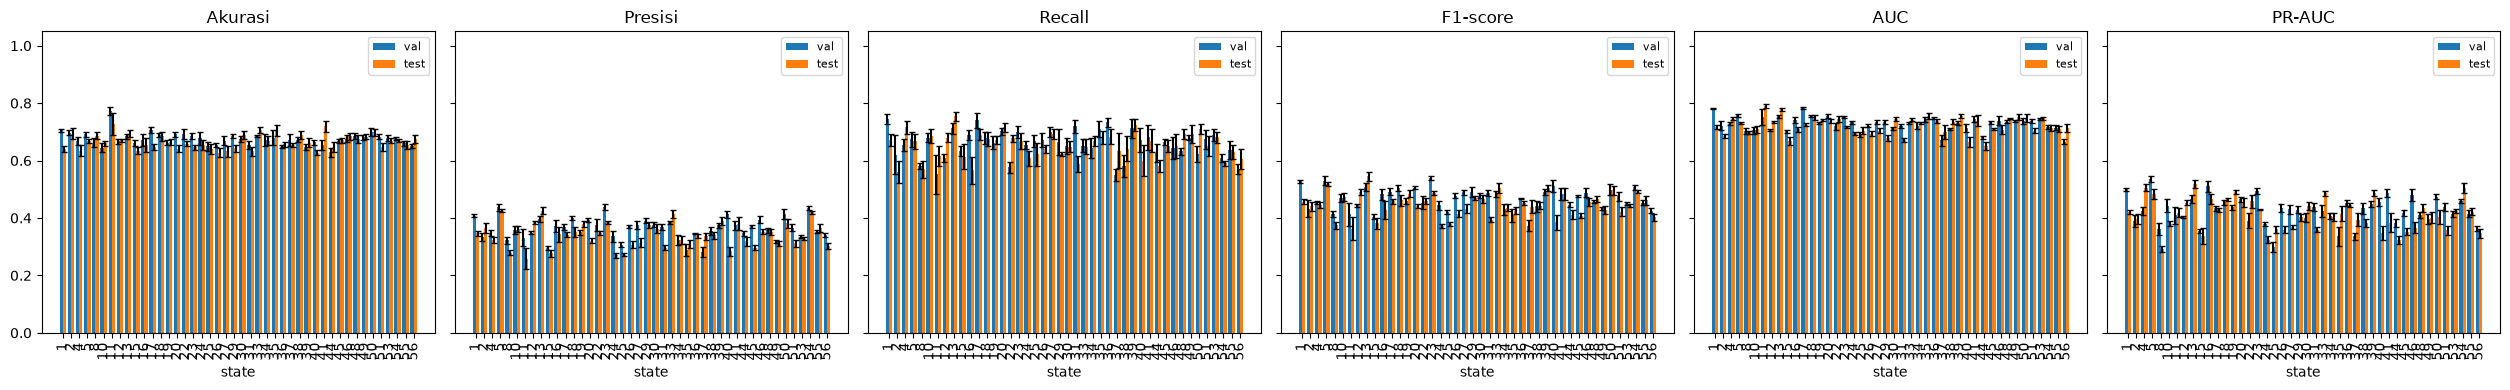


==================== RANKING STATE — VAL (urut F1, mean 5 seed) ====================
       rank_f1  rata2_rank     acc    prec     rec      f1     auc   prauc  f1_std  prauc_std  prauc_lift  n_val  pos_val  pos_rate_val%  n_train  pos_rate_train%
state                                                                                                                                                             
23           1        5.83  0.6855  0.4392  0.6992  0.5393  0.7513  0.4946  0.0073     0.0094        1.88   1003      264          26.32     1763            25.01
5            2        5.50  0.6911  0.4372  0.6740  0.5303  0.7578  0.5355  0.0155     0.0100        2.07    595      154          25.88     1076            25.93
1            3        3.00  0.7050  0.4078  0.7452  0.5271  0.7811  0.4998  0.0046     0.0045        2.27    562      124          22.06      979            24.11
40           4       17.33  0.6633  0.4127  0.6727  0.5114  0.7135  0.4547  0.0210     0.0143      

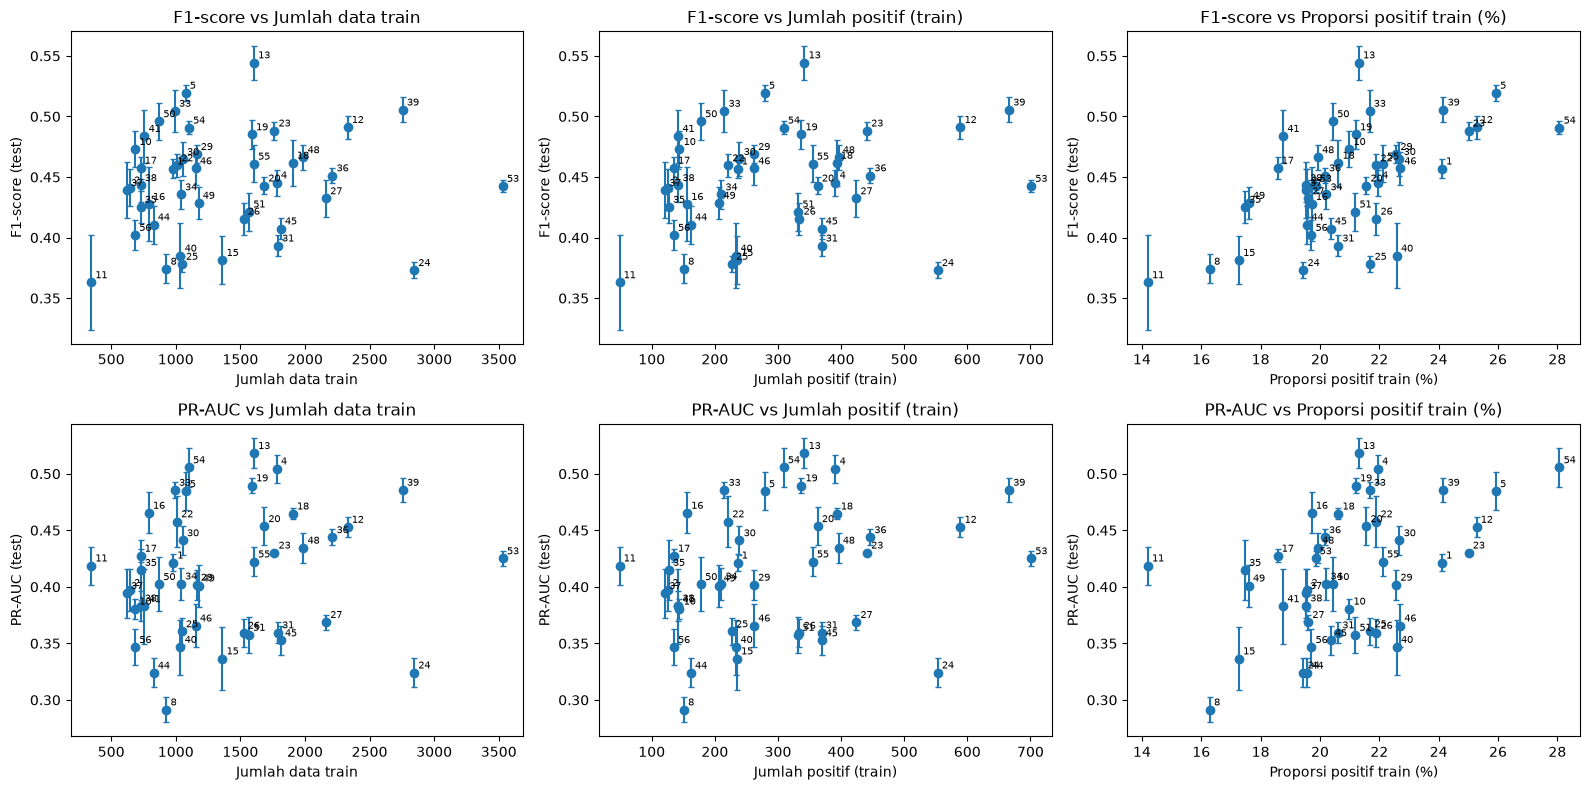

In [3]:

# %%
# ============================================================
# 5. RINGKASAN METRIK (VAL vs TEST), RATA-RATA ANTAR SEED
# ============================================================
def n_split(split):
    return pd.Series({st: len(clients[st][f'y_{split}_t']) for st in clients})
 
 
def ringkas_metrik(split):
    h = HASIL[split][METRIK]                 # sudah mean antar seed
    n = n_split(split).reindex(h.index)
    berbobot = {}
    for m in METRIK:
        ok = h[m].notna()
        berbobot[m] = np.average(h.loc[ok, m], weights=n[ok]) if ok.any() else np.nan
    return pd.DataFrame({
        'Rata-rata (makro)':  h.mean(),
        'Std antar client':   h.std(),
        'Rata-rata berbobot': pd.Series(berbobot),
        'Min':                h.min(),
        'Max':                h.max(),
    }).rename(index=NAMA)
 
 
ringkasan = {s: ringkas_metrik(s) for s in SPLITS}
for s in SPLITS:
    print(f"=== Ringkasan antar client: {s.upper()} (mean {len(SEEDS)} seed) ===")
    print(ringkasan[s].round(4).to_string(), "\n")
 
banding = pd.DataFrame({
    'VAL':  hasil_val[METRIK].mean(),
    'TEST': hasil_test[METRIK].mean(),
}).rename(index=NAMA)
banding['Gap (val-test)'] = banding['VAL'] - banding['TEST']
print("=== Perbandingan rata-rata makro VAL vs TEST ===")
print(banding.round(4).to_string())
 
# Bar chart val vs test per state; error bar = std antar seed
states = hasil_val.index.astype(str)
x = np.arange(len(states))
lebar = 0.4
fig, axes = plt.subplots(1, len(METRIK), figsize=(4.2 * len(METRIK), 4), sharey=True)
for ax, m in zip(axes, METRIK):
    ax.bar(x - lebar / 2, hasil_val[m],  lebar, yerr=HASIL_STD['val'][m],
           capsize=2, label='val')
    ax.bar(x + lebar / 2, hasil_test[m], lebar, yerr=HASIL_STD['test'][m],
           capsize=2, label='test')
    ax.set_title(NAMA[m])
    ax.set_xticks(x)
    ax.set_xticklabels(states, rotation=90)
    ax.set_xlabel('state')
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
 
# %%
# ============================================================
# 6. RANKING STATE (VAL & TEST), BERDASARKAN MEAN ANTAR SEED
# ============================================================
info = pd.DataFrame({
    st: {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    }
    for st, c in clients.items()
}).T
info['pos_rate_train%'] = (100 * info['pos_train'] / info['n_train']).round(2)
info['pos_rate_val%']   = (100 * info['pos_val']   / info['n_val']).round(2)
info['pos_rate_test%']  = (100 * info['pos_test']  / info['n_test']).round(2)
info.index.name = 'state'
 
 
def ranking(split, N=5):
    g = HASIL[split][METRIK].join(info)
    g['f1_std']    = HASIL_STD[split]['f1']
    g['prauc_std'] = HASIL_STD[split]['prauc']
 
    # Ranking utama: F1, tie-breaker PR-AUC (berbasis sort, aman terhadap NaN)
    urut = g.sort_values(['f1', 'prauc'], ascending=False, na_position='last').index
    g['rank_f1'] = pd.Series(np.arange(1, len(urut) + 1), index=urut)
    g['rata2_rank'] = g[METRIK].rank(ascending=False, method='min').mean(axis=1).round(2)
    g['prauc_lift'] = (g['prauc'] / (g[f'pos_rate_{split}%'] / 100)).round(2)
    g = g.sort_values(['rank_f1', 'rata2_rank'])
 
    kolom = (['rank_f1', 'rata2_rank'] + METRIK + ['f1_std', 'prauc_std', 'prauc_lift',
             f'n_{split}', f'pos_{split}', f'pos_rate_{split}%', 'n_train',
             'pos_rate_train%'])
    n = min(N, len(g))
    print(f"\n{'=' * 20} RANKING STATE — {split.upper()} (urut F1, mean {len(SEEDS)} seed) {'=' * 20}")
    print(g[kolom].round(4).to_string())
    print(f"\n--- {n} TERBAIK ({split.upper()}) ---")
    print(g[kolom].head(n).round(4).to_string())
    print(f"\n--- {n} TERENDAH ({split.upper()}) ---")
    print(g[kolom].tail(n).round(4).to_string())
 
    profil = pd.DataFrame({
        f'Top {n}':    g.head(n)[['n_train', f'n_{split}', 'pos_rate_train%']].mean(),
        f'Bottom {n}': g.tail(n)[['n_train', f'n_{split}', 'pos_rate_train%']].mean(),
        'Semua state': g[['n_train', f'n_{split}', 'pos_rate_train%']].mean(),
    }).round(2)
    print(f"\n--- PROFIL DATA ({split.upper()}): atas vs bawah ---")
    print(profil.to_string())
 
    kor = g[['n_train', 'pos_train', 'pos_rate_train%',
             'f1', 'rec', 'auc', 'prauc']].astype(float).corr(method='spearman')
    print(f"\n--- KORELASI SPEARMAN data vs kinerja ({split.upper()}) ---")
    print(kor.loc[['n_train', 'pos_train', 'pos_rate_train%'],
                  ['f1', 'rec', 'auc', 'prauc']].round(3).to_string())
    return g
 
 
gabung_val  = ranking('val')
gabung_test = ranking('test')
 
rk = pd.DataFrame({'rank_val': gabung_val['rank_f1'],
                   'rank_test': gabung_test['rank_f1']})
print("\nKorelasi ranking F1 val vs test (Spearman):",
      round(rk.corr(method='spearman').iloc[0, 1], 3))
 
# Stabilitas ranking antar seed
rank_seed = (hasil_seed['test']
             .pivot(index='state', columns='seed', values='f1')[SEEDS]
             .rank(ascending=False, method='min'))
print("Korelasi Spearman ranking F1 test antar seed (rata-rata pasangan):",
      round(rank_seed.corr(method='spearman').values[np.triu_indices(len(SEEDS), 1)].mean(), 3))
 
# Scatter F1 & PR-AUC (test) vs ukuran/proporsi data, error bar = std antar seed
g = gabung_test
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for r, (met, sd) in enumerate([('f1', 'f1_std'), ('prauc', 'prauc_std')]):
    for ax, xcol, judul in zip(axes[r],
                               ['n_train', 'pos_train', 'pos_rate_train%'],
                               ['Jumlah data train', 'Jumlah positif (train)',
                                'Proporsi positif train (%)']):
        ax.errorbar(g[xcol].astype(float), g[met], yerr=g[sd], fmt='o', capsize=2)
        for st, row in g.iterrows():
            ax.annotate(str(st), (row[xcol], row[met]), fontsize=7,
                        xytext=(3, 3), textcoords='offset points')
        ax.set_xlabel(judul)
        ax.set_ylabel(f'{NAMA[met]} (test)')
        ax.set_title(f'{NAMA[met]} vs {judul}')
plt.tight_layout()
plt.show()
 
# %%
# ============================================================
# 7. SIMPAN HASIL (opsional, hapus komentar untuk mengaktifkan)
# ============================================================
# OUT = CLIENT_DIR.parent / 'hasil_multiseed'
# OUT.mkdir(exist_ok=True)
# for s in SPLITS:
#     hasil_seed[s].to_csv(OUT / f'metrik_{s}_per_seed.csv', index=False)
#     HASIL[s].to_csv(OUT / f'metrik_{s}_mean.csv')
#     HASIL_STD[s].to_csv(OUT / f'metrik_{s}_std.csv')
# gabung_test.to_csv(OUT / 'ranking_test.csv')